**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**:  November 2025

We're going to create a heatmap showing the 

In [1]:
import os

import biom
import numpy as np
import pandas as pd
import scipy
import skbio

from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as mpc
from matplotlib.ticker import StrMethodFormatter
import seaborn as sn

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.phylogeny.actions as q2_tree

%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# Data

In [2]:
meta = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta.set_index('sample-id', inplace=True)

In [3]:
table_q2 = Artifact.load('final-data/02.tables/matched-species-gtdb.qza')

In [4]:
table_a = table_q2.view(biom.Table)
table_a.add_metadata(meta.to_dict(orient='index'), axis='sample')
table_a.filter(lambda v, id_, md: v.sum() >= 1e6, axis='sample')
    # .norm(axis='sample')
table_n = table_a.copy().norm(axis='sample')
table_id = table_n.collapse(lambda id_, md: md['host_subject_id'],
                            axis='sample',
                            norm=True)
table_avg = table_id.collapse(lambda id_, md: 'all',
                             axis='sample',
                             norm=True)
table_avg = table_avg.to_dataframe().sparse.to_dense()
table_avg.sort_values('all', ascending=False, inplace=True)
table_avg2 = table_avg.head(40)

In [5]:
table_avg2

,all
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides_B;s__Bacteroides_B vulgatus,0.062742
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella copri,0.058651
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides;s__Bacteroides uniformis,0.049348
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides_B;s__Bacteroides_B dorei,0.035154
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides;s__Bacteroides ovatus,0.024156
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae;g__Alistipes;s__Alistipes putredinis,0.021030
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Christensenellales;f__CAG-74;g__UBA11524;s__UBA11524 sp000437595,0.020384
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides;s__Bacteroides stercoris,0.019997
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella sp001275135,0.019662
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides;s__Bacteroides caccae,0.014049


In in ideal world, the features would be sorted phylogenetically. So, I'm going to load the three, and get the distance from the most abundant tip, and then from there, the distance from the furtherest clade, to see if we can 

In [6]:
tree_q2 = Artifact.load('final-data/02.tables/matched_tree_gtdb.qza')
taxa_q2 = Artifact.load('final-data/02.tables/matched-taxonomy-gtdb.qza')

In [7]:
taxa = taxa_q2.view(pd.DataFrame)
taxa_abund = taxa.loc[taxa['Taxon'].isin(table_avg2.index)].copy()
taxa_abund['abund'] = taxa_abund['Taxon'].replace(table_avg2['all'].astype(str)).astype(float)
taxa_abund['class'] = taxa_abund['Taxon'].apply(lambda x: x.split(';')[2])
taxa_abund.sort_values(['class', 'abund'], ascending=[True, False], inplace=True)
top_tip = taxa_abund.drop_duplicates('class', keep='first').index.values
top_tip = list(top_tip)
top_tip

['GB.GCA.000433315.1',
 'RS.GCF.000012825.1',
 'GB.GCA.000437595.1',
 'RS.GCF.000411515.1',
 'RS.GCF.000020225.1']

In [8]:
tree_abund_q2, = q2_tree.filter_tree(tree_q2, metadata=Metadata(taxa_abund))

In [9]:
tree_abund = tree_abund_q2.view(skbio.TreeNode)

In [10]:
tt_dist = tree_abund.tip_tip_distances()

In [11]:
tt_dist_l = tt_dist.to_series()
tt_dist_l[tt_dist_l == tt_dist_l.max()]

GB.GCA.003287405.1  RS.GCF.000157935.1    3.54139
dtype: float64

In [12]:
tips_t_order = tree_abund.traverse('GB.GCA.000434395.1', 'RS.GCF.000157935.1')
tips_t_order =[taxa.loc[t.name, 'Taxon'] for t in tips_t_order if t.is_tip()]
tips_t_order

['d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Ruminococcus_D;s__Ruminococcus_D bicirculans',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Faecalibacterium;s__Faecalibacterium prausnitzii_J',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Faecalibacterium;s__Faecalibacterium prausnitzii_D',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Faecalibacterium;s__Faecalibacterium prausnitzii_G',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae;g__Faecalibacterium;s__Faecalibacterium prausnitzii_C',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__CAG-83;s__CAG-83 sp000435555',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__ER4;s__ER4 sp000765235',
 'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Christensenellales;f__CAG-74;g__UBA11524;

## Heatmap?

In [13]:
taxa_colors = {
    'p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae': '#ff7f00',
    'p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae': '#fe9929',
    'p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae': '#fdae6b',
    'p__Firmicutes_A;c__Clostridia;o__Christensenellales;f__CAG-74': '#fec44f',
    'p__Firmicutes_A;c__Other;o__Other;f__Other': '#feeda0',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae': '#4292c6',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae': '#6baed6',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Tannerellaceae': '#9ecae1',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae': '#c6dbef',
    'p__Bacteroidota;c__Other;o__Other;f__Other': '#eff3ff',
    'p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Burkholderiaceae': '#238b45',
    'p__Proteobacteria;c__Alphaproteobacteria;o__RF32;f__CAG-239': '#74c476',
    'p__Proteobacteria;c__Other;o__Other;f__Other': '#c7e9c0',
    'p__Firmicutes;c__Bacilli;o__RFN20;f__CAG-288': '#9E5C00',
    'p__Firmicutes;c__Other;o__Other;f__Other': '#D8C7BE',
    'p__Verrucomicrobiota;c__Verrucomicrobiae;o__Verrucomicrobiales;f__Akkermansiaceae': '#6a51a3',
    'p__Verrucomicrobiota;c__Other;o__Other;f__Other': '#dadaeb',
    'p__Other;c__Other;o__Other;f__Other': '#737373',
    'p__Firmicutes_C;c__Other;o__Other;f__Other': '#737373'
}

In [14]:
table_n.to_dataframe().sparse.to_dense()

,17-763,17-799,18-244,17-676,18-047,18-144,18-238,18-201,18-256,17-082,...,17-670,17-667,17-859,18-203,17-827,18-082,17-678,18-209,18-295,17-669
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella copri,0.000784,1.440876e-04,0.000168,0.289036,0.267904,0.000096,0.315726,0.295533,0.136393,1.566253e-04,...,0.610973,0.236163,0.267054,0.005464,4.325486e-05,0.000391,0.000096,6.397306e-05,1.039001e-04,5.722191e-05
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella sp001275135,0.078165,1.285127e-04,0.000093,0.000097,0.054022,0.000120,0.000134,0.000048,0.000048,1.224035e-04,...,0.000045,0.000080,0.000068,0.000095,3.046166e-05,0.000017,0.228602,1.871912e-05,3.784505e-04,1.325139e-05
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella copri_A,0.000081,7.162222e-05,0.000025,0.026917,0.026483,0.000042,0.030912,0.028041,0.013032,8.538944e-05,...,0.064016,0.025602,0.029166,0.000848,4.494910e-06,0.000593,0.000030,7.847877e-06,2.474668e-05,5.560024e-06
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella sp000434515,0.000009,9.863566e-07,0.000002,0.003063,0.003826,0.000001,0.007651,0.003316,0.001407,7.014919e-07,...,0.006821,0.002802,0.004189,0.000063,4.149148e-07,0.000082,0.000001,7.075954e-07,9.587093e-07,6.023359e-07
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Prevotella;s__Prevotella lascolaii,0.000598,3.838200e-04,0.000143,0.000260,0.000848,0.000929,0.000961,0.000394,0.000377,5.107824e-04,...,0.003071,0.001443,0.000172,0.000572,5.633851e-04,0.000320,0.000594,2.766055e-04,8.442634e-05,2.788815e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
d__Bacteria;p__Patescibacteria;c__Paceibacteria_A;o__Moranbacterales;f__UBA2193;g__UBA2773;s__UBA2773 sp002352465,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
d__Bacteria;p__Patescibacteria;c__Dojkabacteria;o__SC72;f__SC72;g__UBA5209;s__UBA5209 sp002412645,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
d__Bacteria;p__Chloroflexota;c__Dehalococcoidia;o__UBA2979;f__UBA2979;g__UBA6627;s__UBA6627 sp002455955,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00
d__Bacteria;p__Acidobacteriota;c__Acidobacteriae;o__UBA7541;f__UBA7541;g__UBA7541;s__UBA7541 sp001914785,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00


In [15]:
table2 = table_n.to_dataframe().sparse.to_dense().loc[tips_t_order].copy()
table2.mask(table2 < 1e-8, 1e-8, inplace=True)
taxa_order = meta[['abx_code2', 'host_subject_id', 'timepoint']].copy()
table2.columns = pd.MultiIndex.from_frame(taxa_order)
table3 = np.log10(table2).loc[tips_t_order]
table3.sort_index(axis='columns', ascending=True, inplace=True)

In [16]:
taxa_frame = table3.index.to_frame()
taxa_frame['phylum'] = taxa_frame[0].apply(lambda x: x.split(';')[1])
taxa_frame['species'] = taxa_frame[0].apply(lambda x: x.split(';')[-1])
taxa_frame['species'] = taxa_frame['species'].apply(lambda x: x.replace("__", '. ').replace("_", ' '))
taxa_frame['family'] = taxa_frame[0].apply(lambda x: ';'.join(x.split(';')[1:5]))
taxa_frame['family_color'] = taxa_frame['family'].mask(
    ~taxa_frame['family'].isin(taxa_colors.keys()),
    taxa_frame['phylum'].apply(lambda x: f'{x};c__Other;o__Other;f__Other')
    ).replace(taxa_colors)

In [17]:
time_colors = zip(*(sorted(meta['timepoint'].unique()), sn.color_palette(palette='Greys', n_colors=8)))
time_colors = {tp: mpc.to_hex(c) for tp, c in time_colors}
abx_colors = {'0': '#969696', 
             '1': '#009E73',
             '2': '#9D654C', 
             '3': '#4E7705', 
             '4': '#098BD9',
             '5': '#CC79A7'}
abx_names = {'0': 'untreated',
             '1': 'nitrofurantoin', 
             '2': 'pivmecillinam',
             '3': 'co-trimoxazole',
             '4': 'ceftibuten',
             '5': 'ciprofloxacin'}
subject_ids = table3.columns.to_frame()['host_subject_id'].unique()
subject_colors = {
    hsi: mpc.to_hex(c) 
    for hsi, c in zip(*(subject_ids, sn.color_palette('tab20', n_colors=len(subject_ids))))
}

In [18]:
count_size = table3.columns.to_frame().reset_index(drop=True).groupby('abx_code2')['timepoint'].count()

In [19]:
hide_axes = dict(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)

Text(2704.1656666666668, 0.5, 'Log$_{10}$(Relative Abundance)')

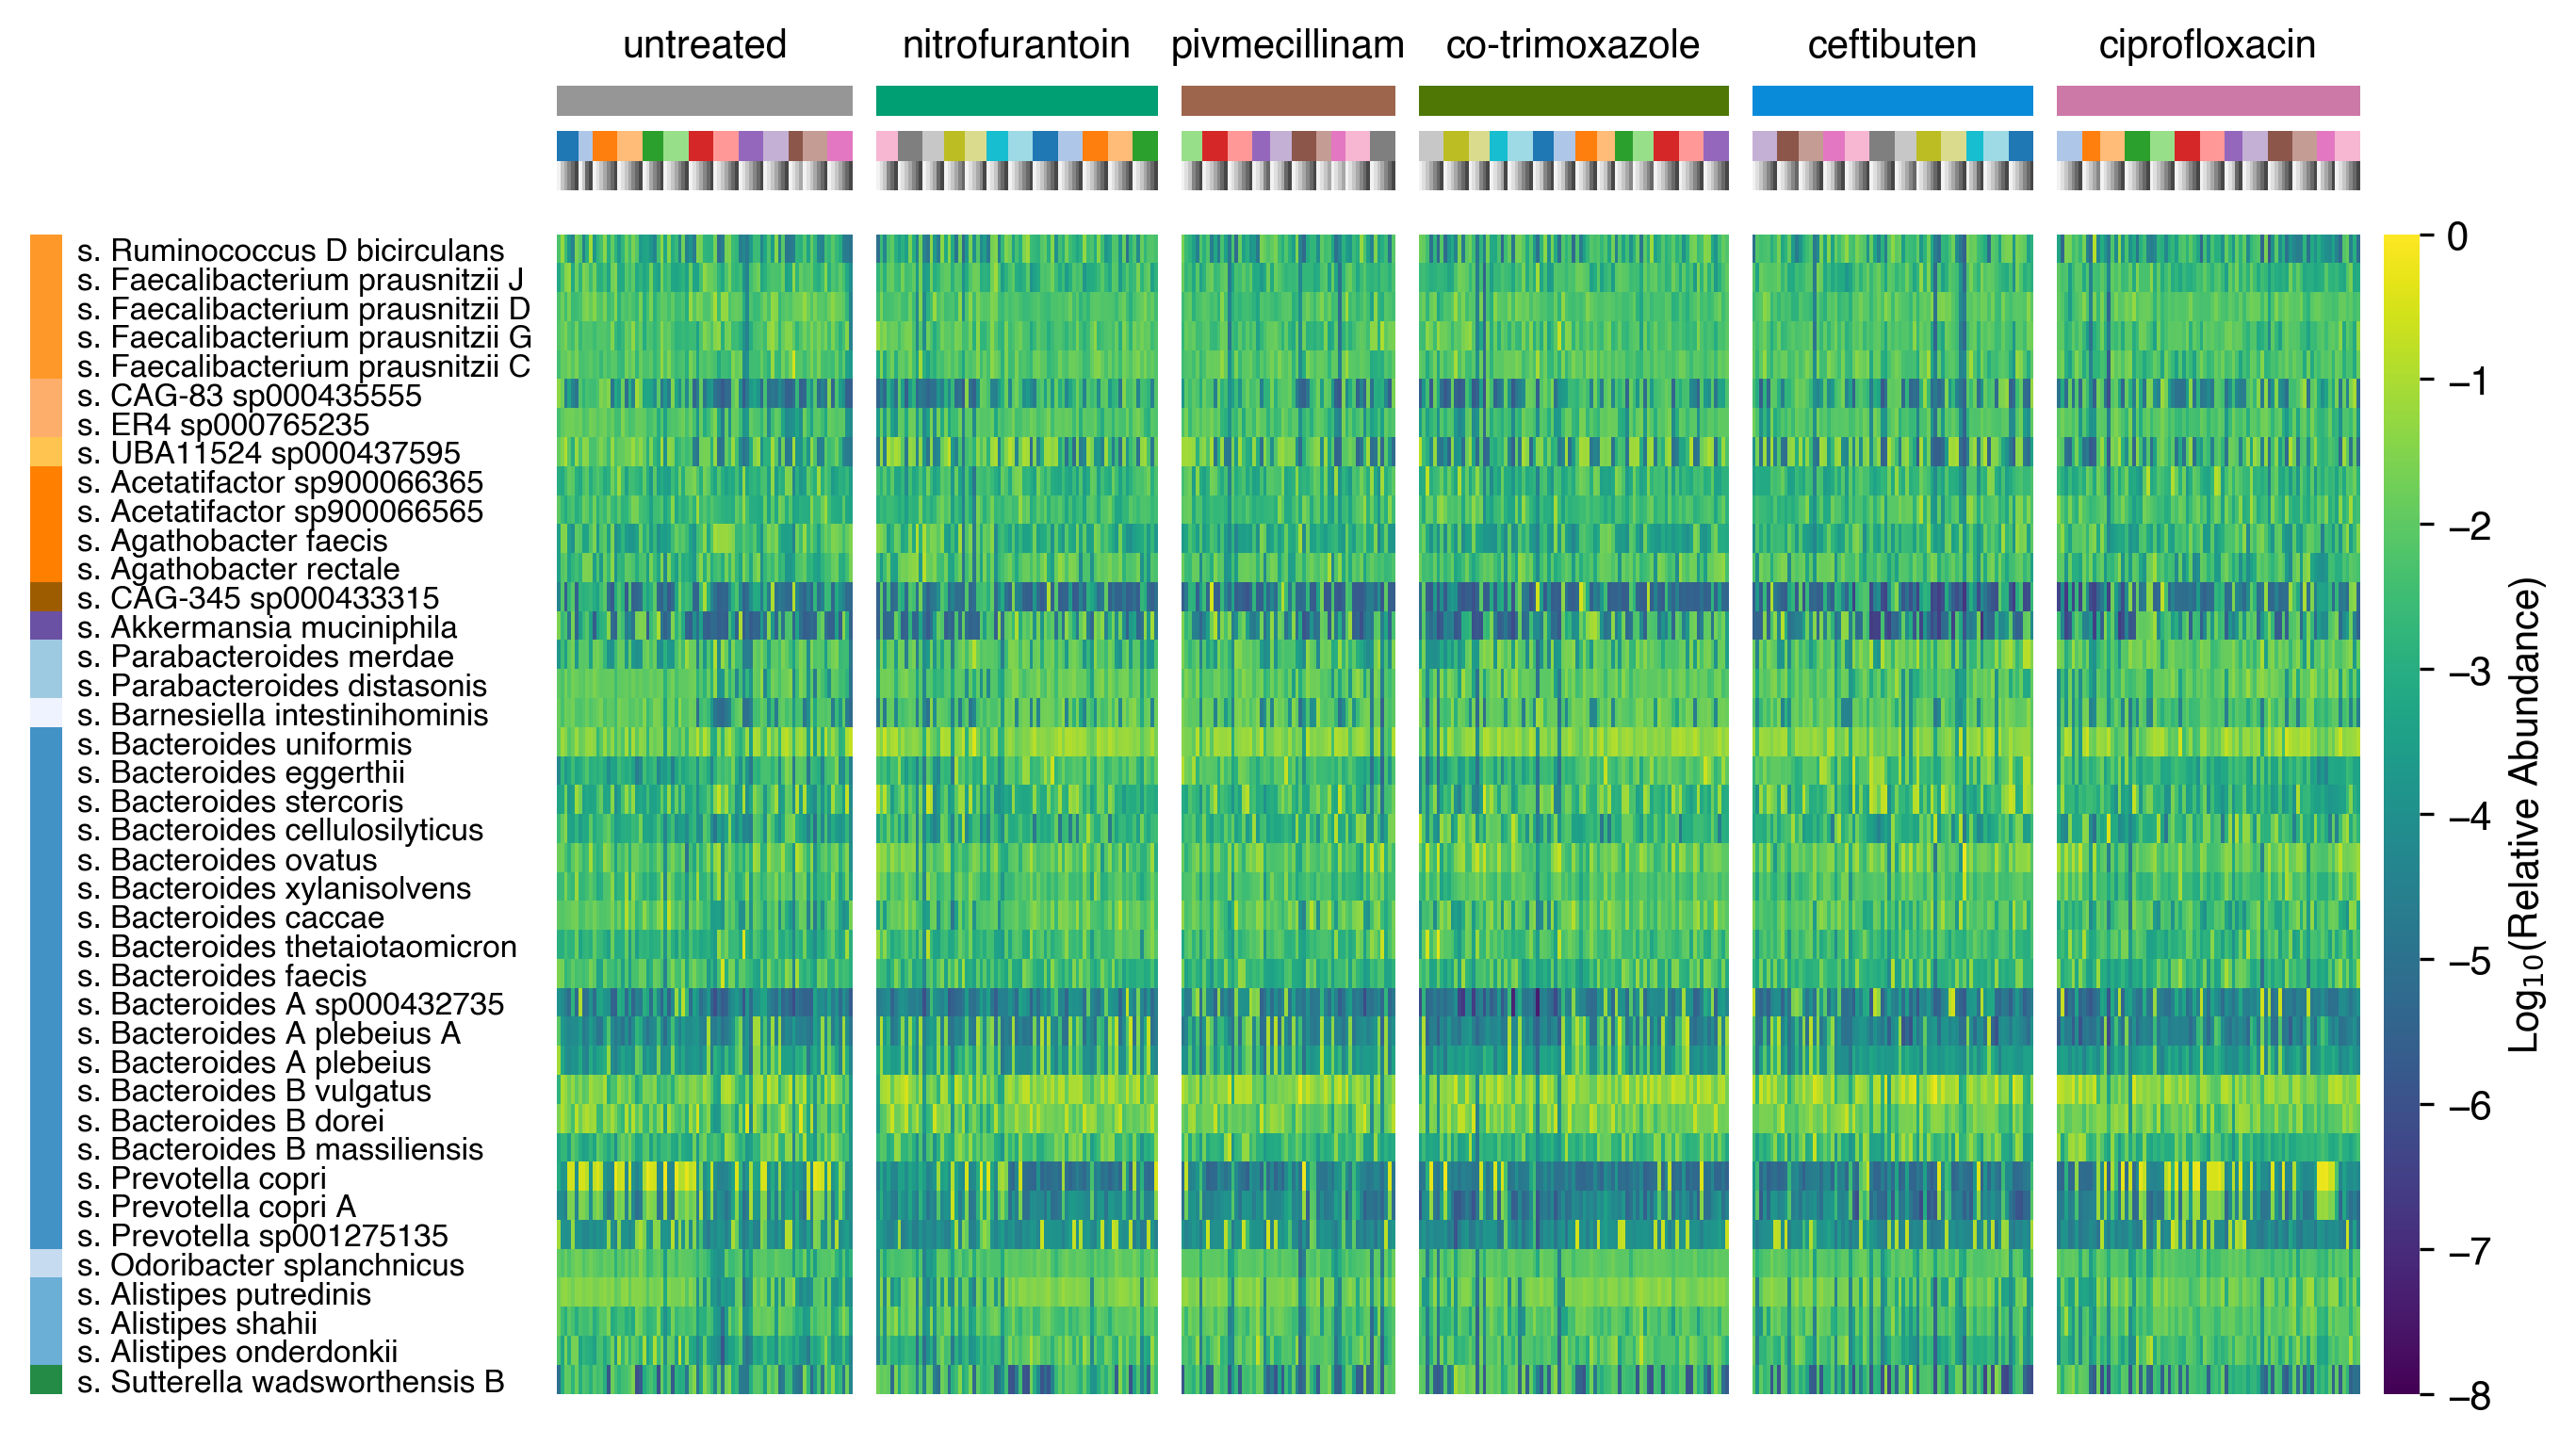

In [20]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(9, 5), facecolor='None')
gs = fig.add_gridspec(2, 8, 
                      height_ratios=[1, 10],
                      width_ratios=np.hstack([10, count_size.values, 10]),
                      )
hm_kwrgs = dict(yticklabels=taxa_frame['species'],
                xticklabels=[],
                vmin=-8, vmax=0,
                cmap='viridis',
                )
axl = fig.add_subplot(gs[1, 0])
axl.bar(bottom=np.ones(len(taxa_frame)).cumsum() - 1,
        height=np.ones(len(taxa_frame)),
        color=taxa_frame['family_color'],
        x=np.zeros(len(taxa_frame)),
       )
axl.xaxis.set_tick_params(**hide_axes)
axl.yaxis.set_tick_params(**hide_axes)
axl.yaxis.set_tick_params(labelsize=8, labelright=True)
sn.despine(ax=axl, left=True, right=True, top=True, bottom=True)

cbar_ax = {'0': dict(cbar=True, cbar_ax=fig.add_subplot(gs[1, -1])),
           '1': dict(cbar=False, cbar_ax=None),
           '2': dict(cbar=False, cbar_ax=None),
           '3': dict(cbar=False, cbar_ax=None),
           '4': dict(cbar=False, cbar_ax=None),
           '5': dict(cbar=False, cbar_ax=None),
            }
for abx, abx_data in table3.T.groupby('abx_code2'):
    ax = fig.add_subplot(gs[1, int(abx) + 1], sharey=axl)
    sn.heatmap(ax=ax, data=abx_data.T, **hm_kwrgs, **cbar_ax[abx])
    ax.yaxis.get_label().set_visible(False)
    ax.xaxis.get_label().set_visible(False)
    ax.xaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(labelleft=False, labelsize=8)
    
    part_ = abx_data.index.to_frame()
    part_['x'] = 1
    part_['x'] = part_['x'].cumsum() - 1
    part_['time_color'] = part_['timepoint'].replace(time_colors)
    part_['abx_color'] = part_['abx_code2'].replace(abx_colors)
    part_['subject_color'] = part_['host_subject_id'].replace(subject_colors)

    axt = fig.add_subplot(gs[0, int(abx) + 1], facecolor='None', sharex=ax)
    axt.xaxis.set_tick_params(**hide_axes)
    axt.yaxis.set_tick_params(**hide_axes)
    sn.despine(ax=axt, left=True, right=True, top=True, bottom=True)
    axt.barh(left=part_['x'], 
             width=1,
             y=part_['x'] * 0 + 0.5,
             height=1, 
             color=part_['time_color'])
    axt.barh(left=part_['x'], 
             width=1,
             y=part_['x'] * 0 + 1.5,
             height=1, 
             color=part_['subject_color'])
    axt.barh(left=part_['x'], 
             width=1,
             y=part_['x'] * 0 + 3,
             height=1, 
             color=part_['abx_color'])
    axt.set_title(abx_names[abx], size=10)

cbar_ax['0']['cbar_ax'].set_ylabel('Log$_{10}$(Relative Abundance)')